# Travel Reimbursement Approval Agent

**Primary assessment notebook.** Run all cells top-to-bottom.

## Setup / README
Install the repository dependencies with `pip install -r requirements.txt`. The deterministic engine works without an API token. For the optional hosted inference demonstration, copy `.env.example` to `.env` and set `HF_TOKEN` locally. Do not commit `.env`.

## Design Notes & Reasoning
- The provided policy set is small and fixed; direct policy lookup is simpler and more auditable than introducing a vector database.
- Currency calculations use `Decimal`; the LLM is not allowed to change decisions or amounts.
- Missing required receipts, non-economy airfare, late claims, unknown categories, and claims exceeding $2,000 route to `MANUAL_REVIEW`.
- Receipts are represented by the attachment flags in Appendix B; OCR and document parsing are outside this prototype.
- A production extension could add duplicate detection, OCR, persistence, authentication, observability, and human-review task management.


## 1. Policy tools and deterministic decision engine

In [1]:

from decimal import Decimal
from datetime import date
import json
import pandas as pd

INELIGIBLE = {"spa","minibar","alcohol","personal_entertainment","in_room_movies","personal_shopping","gifts","traffic_fines","penalties","late_fees"}
ELIGIBLE = {"airfare","lodging","meals","ground_transport","conference_fees","registration"}

def duplicate_detector(raw):
    duplicates = []
    seen = set()
    for item in raw["items"]:
        key = (item["category"].lower(), item["description"].strip().lower(), Decimal(str(item["amount"])))
        if key in seen:
            duplicates.append(f'Possible duplicate item: {item["description"]}')
        seen.add(key)
    return duplicates

def output_validator(result):
    required = {"claim_id","decision","approved_amount","deducted_amount","missing_docs",
                "policy_refs","confidence","explanation","tools_used"}
    errors = []
    if set(result) != required:
        errors.append("Structured result does not contain exactly the required fields.")
    if result["decision"] not in {"APPROVE","PARTIAL_APPROVE","REJECT","MANUAL_REVIEW"}:
        errors.append("Invalid decision value.")
    if result["approved_amount"] < 0 or result["deducted_amount"] < 0:
        errors.append("Amounts must be non-negative.")
    return errors

def evaluate_claim(raw):
    approved, deducted = Decimal("0"), Decimal("0")
    refs, reasons, manual, missing = set(), [], [], []
    all_ineligible = True
    for idx, item in enumerate(raw["items"], 1):
        cat, amount = item["category"].lower(), Decimal(str(item["amount"]))
        required = amount > 25 or cat in {"airfare","lodging"}
        if required and not item.get("receipt_attached", True):
            missing.append(f'Item {idx}: {item["description"]} ({cat})')
        if cat in INELIGIBLE:
            refs.add("POL-CAT-02"); deducted += amount
            reasons.append(f'{item["description"]}: ineligible; deducted ${amount:.2f}.')
            continue
        all_ineligible = False
        if cat == "airfare":
            refs.add("POL-CAT-01")
            refs.add("POL-AIR-01")
            if item.get("airfare_class","economy").lower() not in {"economy","coach"}:
                manual.append("Non-economy airfare requires review for possible pre-approval.")
            else: approved += amount
        elif cat in {"lodging","meals","ground_transport"}:
            refs.add("POL-CAT-01")
            policy = {"lodging":("POL-PD-02",Decimal("200")),
                      "meals":("POL-PD-01",Decimal("75")),
                      "ground_transport":("POL-PD-03",Decimal("50"))}[cat]
            refs.add(policy[0]); cap = policy[1] * int(item.get("quantity_days",1))
            allowed = min(amount,cap); approved += allowed; deducted += amount-allowed
            if amount > cap: reasons.append(f'{item["description"]}: cap applied; ${amount-cap:.2f} deducted.')
        elif cat in ELIGIBLE:
            refs.add("POL-CAT-01")
            approved += amount
        else: manual.append(f"Unrecognized expense category: {cat}.")
    if missing:
        refs.update({"POL-RCT-01","POL-RCT-02"}); manual.append("Required receipt is missing.")
    duplicates = duplicate_detector(raw)
    if duplicates:
        manual.extend(duplicates)
    if any(x["category"].lower() in {"airfare","lodging"} for x in raw["items"]):
        refs.add("POL-RCT-01")
    if (date.fromisoformat(raw["submitted_date"])-date.fromisoformat(raw["expense_date"])).days > 30:
        refs.add("POL-TIME-01"); manual.append("Claim submitted more than 30 days after expense date.")
    if approved > 2000:
        refs.add("POL-APR-03"); manual.append("Reimbursable amount exceeds $2,000; director review required.")
    elif approved > 500: refs.add("POL-APR-02")
    else: refs.add("POL-APR-01")
    if manual: decision = "MANUAL_REVIEW"
    elif all_ineligible: decision = "REJECT"
    elif deducted > 0: decision = "PARTIAL_APPROVE"
    else: decision = "APPROVE"
    explanation = " ".join(reasons+manual) or "All submitted items comply with applicable policy rules."
    if decision == "MANUAL_REVIEW": explanation = "Manual review required. " + explanation
    result = {
      "claim_id":raw["claim_id"],"decision":decision,
      "approved_amount":float(approved.quantize(Decimal("0.01"))),
      "deducted_amount":float(deducted.quantize(Decimal("0.01"))),
      "missing_docs":missing,"policy_refs":sorted(refs),
      "confidence":0.95 if decision != "MANUAL_REVIEW" else 0.78,
      "explanation":explanation,
      "tools_used":["policy_lookup","receipt_completeness_check","reimbursement_calculator","approval_threshold_checker","duplicate_detector","output_validator"]
    }
    validation_errors = output_validator(result)
    if validation_errors:
        raise ValueError("Invalid claim result: " + " ".join(validation_errors))
    return result


## 2. Provided sample claims — Appendix B

In [2]:
SAMPLE_CLAIMS = json.loads(r'''
[
  {
    "claim_id": "CLM-001",
    "employee": "A. Rivera",
    "business_purpose": "Attend 2-day industry conference",
    "expense_date": "2026-06-10",
    "submitted_date": "2026-06-20",
    "items": [
      {
        "category": "airfare",
        "description": "Round-trip economy airfare",
        "amount": "420.00",
        "receipt_attached": true,
        "airfare_class": "economy"
      },
      {
        "category": "lodging",
        "description": "Hotel, 2 nights @ $180",
        "amount": "360.00",
        "receipt_attached": true,
        "quantity_days": 2
      },
      {
        "category": "meals",
        "description": "Meals, 3 days @ ~$60/day",
        "amount": "180.00",
        "receipt_attached": true,
        "quantity_days": 3
      },
      {
        "category": "conference_fees",
        "description": "Conference registration",
        "amount": "150.00",
        "receipt_attached": true
      }
    ]
  },
  {
    "claim_id": "CLM-002",
    "employee": "B. Osei",
    "business_purpose": "Weekend hotel stay",
    "expense_date": "2026-06-14",
    "submitted_date": "2026-06-25",
    "items": [
      {
        "category": "spa",
        "description": "Hotel spa package",
        "amount": "300.00",
        "receipt_attached": true
      },
      {
        "category": "minibar",
        "description": "In-room minibar",
        "amount": "80.00",
        "receipt_attached": true
      }
    ]
  },
  {
    "claim_id": "CLM-003",
    "employee": "C. Nakamura",
    "business_purpose": "Client site visit",
    "expense_date": "2026-06-08",
    "submitted_date": "2026-06-22",
    "items": [
      {
        "category": "airfare",
        "description": "Round-trip economy airfare",
        "amount": "300.00",
        "receipt_attached": true,
        "airfare_class": "economy"
      },
      {
        "category": "lodging",
        "description": "Hotel, 2 nights @ $250",
        "amount": "500.00",
        "receipt_attached": true,
        "quantity_days": 2
      },
      {
        "category": "meals",
        "description": "Meals, 2 days @ $70/day",
        "amount": "140.00",
        "receipt_attached": true,
        "quantity_days": 2
      }
    ]
  },
  {
    "claim_id": "CLM-004",
    "employee": "D. Fischer",
    "business_purpose": "International vendor negotiation",
    "expense_date": "2026-06-16",
    "submitted_date": "2026-06-28",
    "items": [
      {
        "category": "airfare",
        "description": "Business-class international airfare",
        "amount": "2400.00",
        "receipt_attached": true,
        "airfare_class": "business"
      },
      {
        "category": "lodging",
        "description": "Hotel, 3 nights",
        "amount": "600.00",
        "receipt_attached": false,
        "quantity_days": 3
      }
    ]
  },
  {
    "claim_id": "CLM-005",
    "employee": "E. Haddad",
    "business_purpose": "Client dinner / business development",
    "expense_date": "2026-06-11",
    "submitted_date": "2026-06-24",
    "items": [
      {
        "category": "meals",
        "description": "Client dinner for 4",
        "amount": "220.00",
        "receipt_attached": false,
        "quantity_days": 1
      }
    ]
  }
]
''')

## 3. Evaluate all five claims

In [3]:
results = [evaluate_claim(claim) for claim in SAMPLE_CLAIMS]
len(results)

5

## 4. Dashboard

,claim_id,decision,approved_amount,deducted_amount
0,CLM-001,APPROVE,1110.0,0.0
1,CLM-002,REJECT,0.0,380.0
2,CLM-003,PARTIAL_APPROVE,840.0,100.0
3,CLM-004,MANUAL_REVIEW,600.0,0.0
4,CLM-005,MANUAL_REVIEW,75.0,145.0


,claim_count
decision,
APPROVE,1
MANUAL_REVIEW,2
PARTIAL_APPROVE,1
REJECT,1


<Axes: title={'center': 'Approved vs Deducted Amounts'}, xlabel='decision', ylabel='USD'>

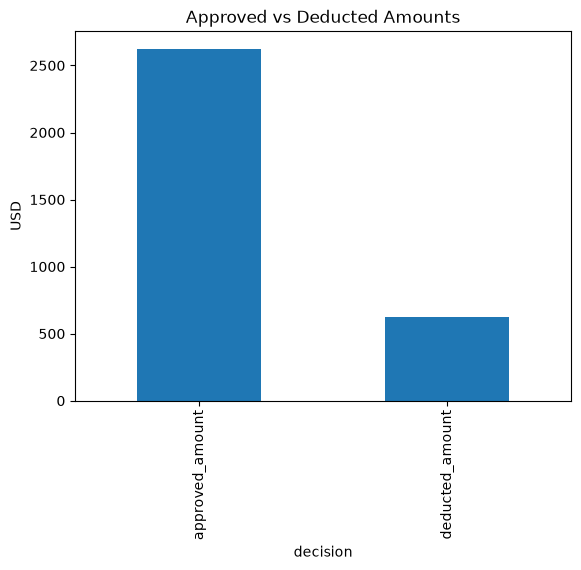

In [4]:
dashboard = pd.DataFrame([{
    "claim_id": r["claim_id"], "decision": r["decision"],
    "approved_amount": r["approved_amount"], "deducted_amount": r["deducted_amount"]
} for r in results])
display(dashboard)
display(dashboard.groupby("decision").size().rename("claim_count").to_frame())
dashboard.groupby("decision").size().plot(kind="bar", title="Decision Breakdown", ylabel="Claim Count")
dashboard[["approved_amount", "deducted_amount"]].sum().plot(kind="bar", title="Approved vs Deducted Amounts", ylabel="USD")


## 5. Final structured output
Exactly the nine fields requested in the assignment are emitted for each sample claim.

In [5]:
print(json.dumps(results, indent=2))

[
  {
    "claim_id": "CLM-001",
    "decision": "APPROVE",
    "approved_amount": 1110.0,
    "deducted_amount": 0.0,
    "missing_docs": [],
    "policy_refs": [
      "POL-AIR-01",
      "POL-APR-02",
      "POL-CAT-01",
      "POL-PD-01",
      "POL-PD-02",
      "POL-RCT-01"
    ],
    "confidence": 0.95,
    "explanation": "All submitted items comply with applicable policy rules.",
    "tools_used": [
      "policy_lookup",
      "receipt_completeness_check",
      "reimbursement_calculator",
      "approval_threshold_checker",
      "duplicate_detector",
      "output_validator"
    ]
  },
  {
    "claim_id": "CLM-002",
    "decision": "REJECT",
    "approved_amount": 0.0,
    "deducted_amount": 380.0,
    "missing_docs": [],
    "policy_refs": [
      "POL-APR-01",
      "POL-CAT-02"
    ],
    "confidence": 0.95,
    "explanation": "Hotel spa package: ineligible; deducted $300.00. In-room minibar: ineligible; deducted $80.00.",
    "tools_used": [
      "policy_lookup",
      